# TAREA 2 - Nuestro modelo de ML
### Terremotos: ¿podemos predecir cuántos sismos habrá el próximo mes?

**Integrantes:** Alexis Baud y Clotilde Gand Watteau

---

En la Tarea 1 nos preguntamos si "últimamente está temblando más". Vimos que el número de terremotos registrados
aumenta mucho con el tiempo, pero que gran parte de ese aumento se debe a que **detectamos mejor los sismos pequeños**,
y no a que haya más actividad real.

En esta tarea damos un paso más: vamos a construir un **modelo de Machine Learning** que intenta predecir el
**número de terremotos de un mes** a partir de lo que pasó en los meses anteriores. Después vamos a evaluarlo con
espíritu crítico: ¿funciona?, ¿dónde se equivoca?, ¿qué tan confiable es?

**Estructura del notebook**
1. Definición del problema y preparación de los datos
2. Algoritmo, separación train/test y entrenamiento
3. Evaluación del desempeño
4. Experimento: ¿qué pasa si cambiamos la profundidad del árbol?
5. Auditoría del modelo
6. Conclusiones

In [ ]:
# Librerías que vamos a usar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Estilo general de los gráficos
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 12

# Semilla para que los resultados sean reproducibles
SEMILLA = 42

## 1. Definición del problema

**Target :** el número de terremotos de magnitud ≥ 5.0 que ocurren en un mes.

**Features :** el número de terremotos de magnitud ≥ 5.0 de los 3 meses anteriores (`n_mes_1`, `n_mes_2`, `n_mes_3`).

**Tipo de problema:** **regresión**, porque el target es un número (una cantidad) y no una categoría.

**¿Por qué creemos que los datos pueden contener información útil?**
Los terremotos grandes producen réplicas durante varias semanas. Por eso, si un mes hubo muchos sismos,
es posible que el mes siguiente también haya más de lo normal. Si eso es cierto, el pasado reciente
ayudaría a predecir el futuro cercano.

**¿Por qué magnitud ≥ 5.0 y por qué desde 1973?** (lo justificamos con datos en la siguiente sección)
En la Tarea 1 vimos que el catálogo no es parejo en el tiempo: antes de 1973 se registraban pocos sismos y
los instrumentos eran peores. Si contáramos todos los sismos, el modelo aprendería el "cambio de instrumentos"
y no el comportamiento de la Tierra. Por eso nos quedamos con un periodo y un umbral de magnitud donde
el catálogo es estable.

### 1.1 Carga y limpieza de los datos
Repetimos las mismas transformaciones de la Tarea 1 (fecha, duplicados). Además, filtramos el tipo de evento:
el catálogo incluye **explosiones nucleares** y otros eventos que no son terremotos naturales, y no queremos que
contaminen el conteo.

In [ ]:
# Cargamos el archivo (debe estar en la misma carpeta que el notebook)
datos = pd.read_csv("earthquakes_usgs.csv")

# Convertimos la fecha a formato datetime, igual que en la Tarea 1
datos["fecha"] = pd.to_datetime(datos["time"], format="ISO8601")
datos = datos.drop_duplicates()

print("Filas en el catálogo:", len(datos))
print()
print("Tipos de evento:")
print(datos["type"].value_counts())

Filas en el catálogo: 310535

Tipos de evento:
type
earthquake           309821
nuclear explosion       614
volcanic eruption        71
explosion                16
mine collapse             6
rock burst                3
landslide                 2
quarry blast              1
other event               1
Name: count, dtype: int64


In [ ]:
# Nos quedamos solo con los terremotos naturales
datos = datos[datos["type"] == "earthquake"].copy()

# Creamos columnas de año y de mes (el mes lo guardamos como fecha del día 1)
datos["anio"] = datos["fecha"].dt.year
datos["mes"] = datos["fecha"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()

print("Terremotos naturales:", len(datos))
print("Último evento del catálogo:", datos["fecha"].max())

Terremotos naturales: 309821
Último evento del catálogo: 2026-08-26 14:25:41.270000+00:00


### 1.2 ¿Desde cuándo y desde qué magnitud el catálogo es confiable?
Contamos los terremotos por año con tres umbrales de magnitud. Si el catálogo fuera completo, el número de
sismos grandes debería ser más o menos estable. Usamos escala logarítmica para poder ver las tres curvas juntas.

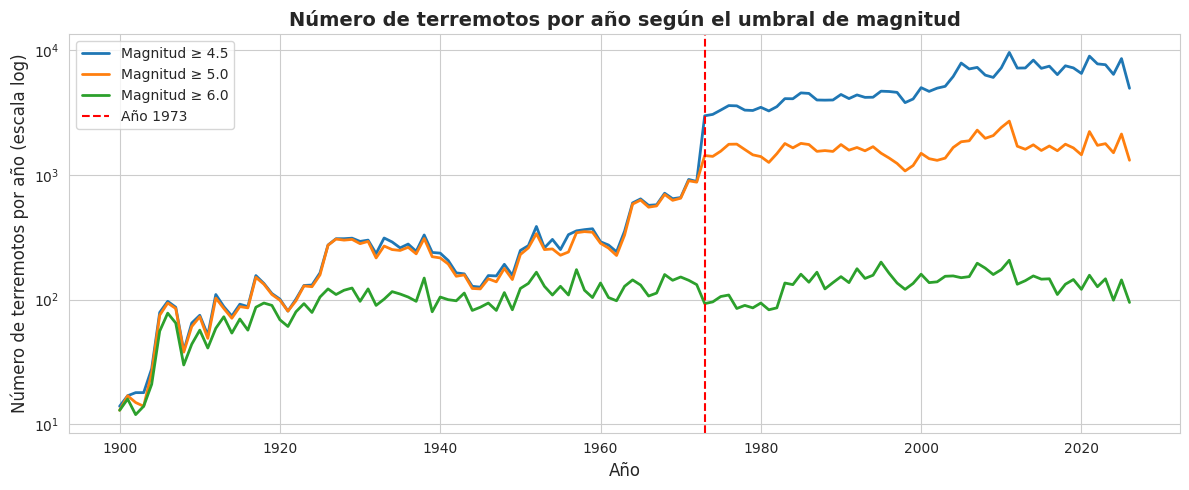

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

colores = {4.5: "tab:blue", 5.0: "tab:orange", 6.0: "tab:green"}
for umbral, color in colores.items():
    conteo = datos[datos["mag"] >= umbral].groupby("anio").size()
    ax.plot(conteo.index, conteo.values, color=color, linewidth=2, label=f"Magnitud ≥ {umbral}")

ax.axvline(1973, color="red", linestyle="--", linewidth=1.5, label="Año 1973")
ax.set_yscale("log")
ax.set_title("Número de terremotos por año según el umbral de magnitud")
ax.set_xlabel("Año")
ax.set_ylabel("Número de terremotos por año (escala log)")
ax.legend()
plt.tight_layout()
plt.show()

**Qué vemos:**
- Antes de 1973, con magnitud ≥ 4.5 y ≥ 5.0, se registraban muy pocos sismos y la curva sube lentamente con los años.
- En 1973 hay un salto fuerte (el mismo "resultado inesperado" que vimos en la Tarea 1).
- Con magnitud ≥ 4.5 la curva sigue cambiando mucho después de 1973 (el catálogo para sismos pequeños no es estable).
- Con magnitud ≥ 5.0 la serie es bastante estable desde 1973.

**Decisión:** usamos terremotos de **magnitud ≥ 5.0**, desde **enero de 1973 hasta diciembre de 2025**.
Dejamos fuera 2026 porque el año está incompleto (el catálogo termina en agosto).

### 1.3 Construcción de la serie mensual
Contamos cuántos terremotos de magnitud ≥ 5.0 hubo en cada mes. Los meses sin ningún sismo cuentan como 0.

In [ ]:
# Filtramos magnitud y periodo
sismos5 = datos[(datos["mag"] >= 5.0) & (datos["anio"] >= 1973) & (datos["anio"] <= 2025)].copy()

# Todos los meses entre 1973 y 2025
todos_los_meses = pd.date_range("1973-01-01", "2025-12-01", freq="MS")

# Contamos sismos por mes (si un mes no tiene sismos, ponemos 0)
serie = sismos5.groupby("mes").size().reindex(todos_los_meses, fill_value=0)

print("Número de meses:", len(serie))
print(serie.describe().round(1))

Número de meses: 636
count    636.0
mean     137.8
std       46.4
min       61.0
25%      111.8
50%      131.0
75%      151.0
max      701.0
dtype: float64


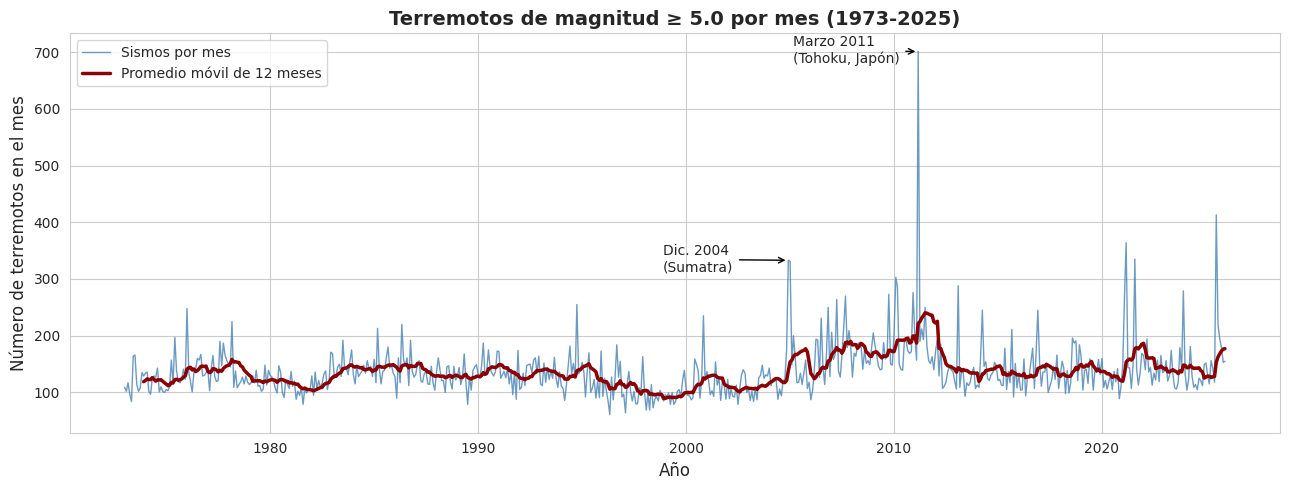

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(serie.index, serie.values, color="steelblue", linewidth=1, alpha=0.8, label="Sismos por mes")
ax.plot(serie.index, serie.rolling(12).mean(), color="darkred", linewidth=2.5, label="Promedio móvil de 12 meses")

# Marcamos los dos meses más extremos de la serie
for fecha, texto in [("2011-03-01", "Marzo 2011\n(Tohoku, Japón)"), ("2004-12-01", "Dic. 2004\n(Sumatra)")]:
    valor = serie[fecha]
    ax.annotate(texto, xy=(pd.Timestamp(fecha), valor), xytext=(pd.Timestamp(fecha) - pd.Timedelta(days=2200), valor - 20),
                arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)

ax.set_title("Terremotos de magnitud ≥ 5.0 por mes (1973-2025)")
ax.set_xlabel("Año")
ax.set_ylabel("Número de terremotos en el mes")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Desde 1973 la serie no muestra una tendencia creciente sostenida: oscila alrededor de ~138 sismos por mes.
  Hay periodos más bajos (fines de los años 90) y más altos (2005-2012), pero la media móvil vuelve siempre al mismo nivel.
  Esto ya matiza la idea de que "está temblando más".
- Hay picos muy altos y aislados, por ejemplo marzo de 2011 (terremoto de Tohoku, con cientos de réplicas).
  Son meses "excepcionales" que van a ser difíciles de predecir.

### 1.4 Creación de las features
Para cada mes, creamos tres columnas con el número de sismos de 1, 2 y 3 meses antes. Usamos `shift`, que
desplaza la serie hacia abajo. Así, cada fila solo contiene información del pasado: no hay forma de que
el modelo "vea" el futuro.

In [ ]:
df = pd.DataFrame({"n_sismos": serie})            # target: sismos del mes
df["n_mes_1"] = serie.shift(1)                    # sismos 1 mes antes
df["n_mes_2"] = serie.shift(2)                    # sismos 2 meses antes
df["n_mes_3"] = serie.shift(3)                    # sismos 3 meses antes

# Las 3 primeras filas no tienen 3 meses previos: las eliminamos
df = df.dropna()

FEATURES = ["n_mes_1", "n_mes_2", "n_mes_3"]
TARGET = "n_sismos"

print("Tamaño de la tabla:", df.shape)
df.head()

Tamaño de la tabla: (633, 4)


,n_sismos,n_mes_1,n_mes_2,n_mes_3
1973-04-01,97,117.0,102.0,109.0
1973-05-01,84,97.0,117.0,102.0
1973-06-01,164,84.0,97.0,117.0
1973-07-01,166,164.0,84.0,97.0
1973-08-01,115,166.0,164.0,84.0


## 2. Algoritmo, separación train/test y entrenamiento

### 2.1 Algoritmo elegido: árbol de decisión (para regresión)
Elegimos un **árbol de decisión** porque:
- Es fácil de entender y de explicar: hace preguntas del tipo "¿el mes anterior tuvo más de 150 sismos?" y
  la predicción es el promedio de los meses que caen en cada rama.
- No necesita escalar las variables.
- Tiene un hiperparámetro muy claro, la profundidad máxima (`max_depth`), que controla qué tan complejo es el
  modelo. Esto nos permite estudiar sobreajuste y subajuste en el experimento.

Para el modelo inicial usamos `max_depth = 3`, un árbol pequeño y simple.

### 2.2 Separación entrenamiento / test
Como los datos son una serie temporal, no hacemos una separación aleatoria. Si mezcláramos los meses al azar,
el modelo podría entrenar con meses de 2020 para predecir 2015, es decir, "usar el futuro para predecir el pasado".
Eso es una forma de *data leakage* y daría resultados demasiado optimistas.

Hacemos una separación **cronológica** (~80 % / 20 %):
- **Entrenamiento:** de abril de 1973 a diciembre de 2013.
- **Test:** de enero de 2014 a diciembre de 2025 (12 años que el modelo nunca ve al entrenar).

**Sobre el data leakage:** el árbol no necesita ninguna transformación que aprenda parámetros de los datos
(no escalamos, no imputamos), y las features solo usan información pasada. Por lo tanto, no hay fuga de información.

In [ ]:
# Separación cronológica
train = df.loc[:"2013-12-31"]
test = df.loc["2014-01-01":]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Entrenamiento: {len(train)} meses ({train.index.min():%m/%Y} a {train.index.max():%m/%Y})")
print(f"Test:          {len(test)} meses ({test.index.min():%m/%Y} a {test.index.max():%m/%Y})")

Entrenamiento: 489 meses (04/1973 a 12/2013)
Test:          144 meses (01/2014 a 12/2025)


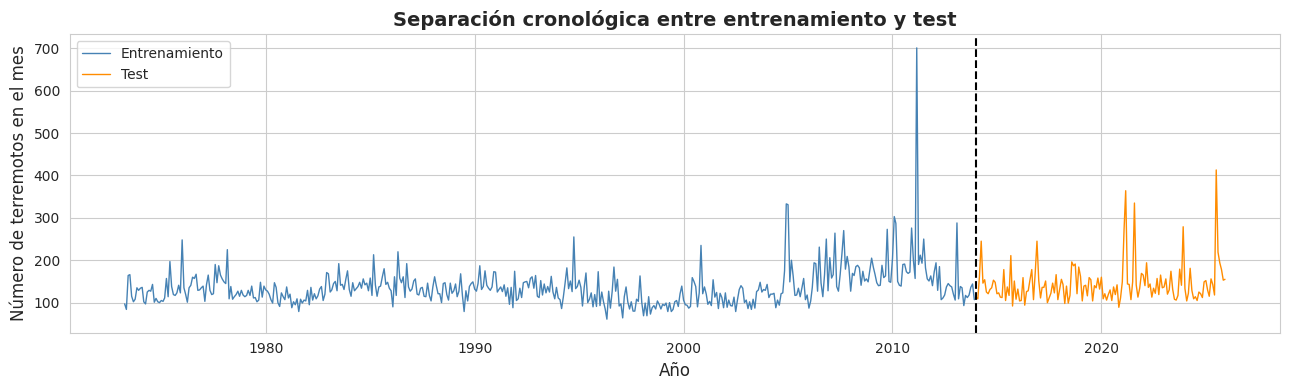

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train.index, y_train, color="steelblue", linewidth=1, label="Entrenamiento")
ax.plot(test.index, y_test, color="darkorange", linewidth=1, label="Test")
ax.axvline(pd.Timestamp("2014-01-01"), color="black", linestyle="--", linewidth=1.5)
ax.set_title("Separación cronológica entre entrenamiento y test")
ax.set_xlabel("Año")
ax.set_ylabel("Número de terremotos en el mes")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 2.3 Entrenamiento del modelo inicial

In [ ]:
modelo = DecisionTreeRegressor(max_depth=3, random_state=SEMILLA)
modelo.fit(X_train, y_train)

# Las reglas que aprendió el árbol (útil para entender qué hace)
print(export_text(modelo, feature_names=FEATURES))

|--- n_mes_1 <= 144.50
|   |--- n_mes_1 <= 110.50
|   |   |--- n_mes_2 <= 104.50
|   |   |   |--- value: [102.58]
|   |   |--- n_mes_2 >  104.50
|   |   |   |--- value: [120.28]
|   |--- n_mes_1 >  110.50
|   |   |--- n_mes_2 <= 140.50
|   |   |   |--- value: [127.03]
|   |   |--- n_mes_2 >  140.50
|   |   |   |--- value: [144.39]
|--- n_mes_1 >  144.50
|   |--- n_mes_3 <= 274.50
|   |   |--- n_mes_2 <= 147.50
|   |   |   |--- value: [142.86]
|   |   |--- n_mes_2 >  147.50
|   |   |   |--- value: [172.43]
|   |--- n_mes_3 >  274.50
|   |   |--- n_mes_3 <= 289.50
|   |   |   |--- value: [701.00]
|   |   |--- n_mes_3 >  289.50
|   |   |   |--- value: [174.00]



Cada línea es una pregunta sobre una feature. Al final de cada rama (`value`) está el número de sismos que el
árbol predice: es el promedio de los meses de entrenamiento que llegaron a esa hoja.

## 3. Evaluación del desempeño

### 3.1 Métricas elegidas
- **MAE (error absoluto medio):** el promedio de cuánto nos equivocamos, en la misma unidad que el target  (sismos por mes). Es fácil de interpretar: "en promedio, el modelo se equivoca en X sismos". Además, no
  exagera el peso de los pocos meses extremos.
- **RMSE:** parecido al MAE, pero castiga más los errores grandes. Comparar MAE y RMSE nos dice si hay errores muy grandes.
- **R²:** compara el modelo con la predicción más simple posible (siempre predecir el promedio). Si R² = 0, el
  modelo no es mejor que predecir el promedio; si es negativo, es peor.

### 3.2 Modelos de referencia (baselines)
Un modelo solo es útil si supera a una predicción muy simple. Usamos dos:
1. **Promedio del entrenamiento:** siempre predecir el promedio histórico.
2. **Mes anterior:** predecir que este mes habrá lo mismo que el mes pasado.

In [ ]:
def calcular_metricas(y_real, y_pred):
    # Devuelve MAE, RMSE y R2 en un diccionario
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred),
    }

# Predicciones del árbol
pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

# Baselines (evaluados en test)
pred_promedio = np.full(len(y_test), y_train.mean())
pred_mes_anterior = X_test["n_mes_1"].values

resultados = pd.DataFrame({
    "Árbol (train)": calcular_metricas(y_train, pred_train),
    "Árbol (test)": calcular_metricas(y_test, pred_test),
    "Baseline: promedio (test)": calcular_metricas(y_test, pred_promedio),
    "Baseline: mes anterior (test)": calcular_metricas(y_test, pred_mes_anterior),
}).T.round(2)

resultados

,MAE,RMSE,R2
Árbol (train),23.56,32.94,0.49
Árbol (test),30.51,47.43,-0.03
Baseline: promedio (test),28.34,47.49,-0.03
Baseline: mes anterior (test),39.46,59.38,-0.61


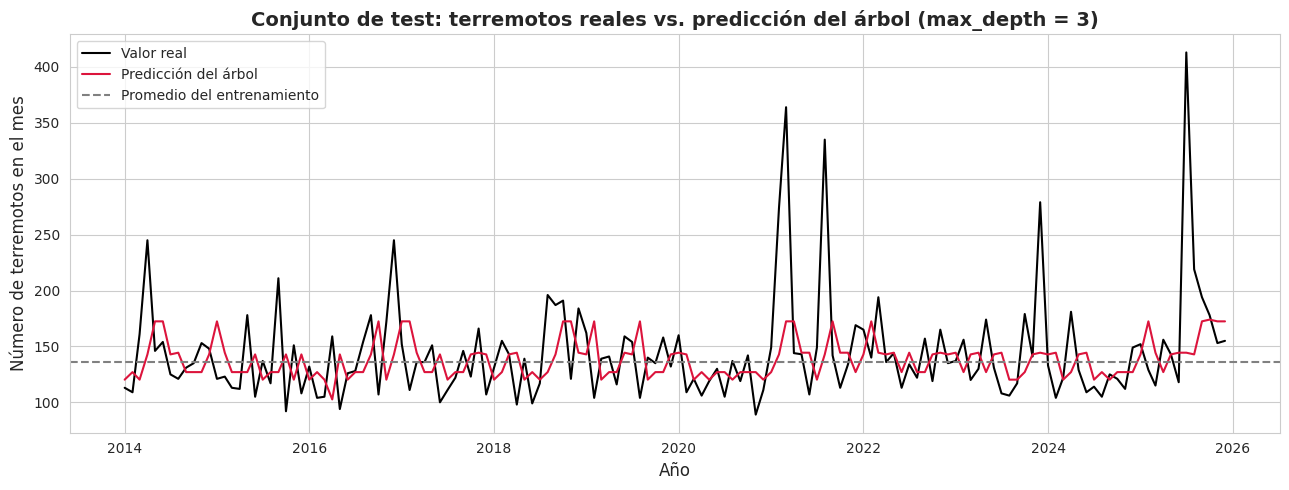

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test.index, y_test, color="black", linewidth=1.5, label="Valor real")
ax.plot(test.index, pred_test, color="crimson", linewidth=1.5, label="Predicción del árbol")
ax.axhline(y_train.mean(), color="gray", linestyle="--", label="Promedio del entrenamiento")
ax.set_title("Conjunto de test: terremotos reales vs. predicción del árbol (max_depth = 3)")
ax.set_xlabel("Año")
ax.set_ylabel("Número de terremotos en el mes")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación**
- En entrenamiento, el árbol se equivoca en promedio ~24 sismos por mes y su R² es ≈ 0.49: ajusta razonablemente bien.
- En test, el error sube a ~31 sismos por mes y el R² cae a ≈ 0 (ligeramente negativo).
- El árbol queda **un poco peor que el baseline del promedio** en MAE (30.5 contra 28.3), **igual** en RMSE (≈ 47) y mejor que
  el baseline del "mes anterior" (MAE ≈ 39). Es decir, no logramos mejorar a la predicción más simple.
- Gráficamente, la predicción del árbol se mueve poco, solo entre ~100 y ~175 sismos, y reacciona un mes tarde: sube
  después del pico, no antes. Los meses extremos (2021, 2025) quedan completamente fuera de lo que el modelo puede anticipar.

## 4. Experimento: la profundidad máxima del árbol

Modificamos un aspecto del modelo: `max_depth`. Todo lo demás se mantiene igual
(mismas features, misma separación train/test, misma semilla).

### 4.1 Predicción (antes de experimentar)
Un árbol más profundo hace más preguntas y puede crear hojas muy pequeñas, hasta memorizar cada mes del entrenamiento.
Por eso esperamos que, al aumentar la profundidad:
- el error en **entrenamiento disminuya** (el árbol se ajusta cada vez más a los datos que ya vio);
- el error en **test aumente** (el árbol aprende ruido y casos particulares, y generaliza peor): **sobreajuste**.

Además, como la serie mensual de sismos es muy ruidosa, esperamos que el sobreajuste aparezca rápido.
Y para profundidades muy pequeñas (1 o 2) esperamos un modelo simple, parecido al promedio.

### 4.2 Experimento
Entrenamos árboles con distintas profundidades y guardamos el error en entrenamiento y en test.

In [ ]:
# Probamos distintas profundidades (None = sin límite)
profundidades = [1, 2, 3, 5, 7, 10, None]
filas = []

for prof in profundidades:
    arbol = DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA)
    arbol.fit(X_train, y_train)

    m_train = calcular_metricas(y_train, arbol.predict(X_train))
    m_test = calcular_metricas(y_test, arbol.predict(X_test))

    filas.append({
        "max_depth": "sin límite" if prof is None else prof,
        "Número de hojas": arbol.get_n_leaves(),
        "MAE train": m_train["MAE"],
        "MAE test": m_test["MAE"],
        "R2 train": m_train["R2"],
        "R2 test": m_test["R2"],
    })

tabla_exp = pd.DataFrame(filas).round(2)
tabla_exp

,max_depth,Número de hojas,MAE train,MAE test,R2 train,R2 test
0,1,2,27.10,30.80,0.13,-0.05
1,2,4,26.08,30.85,0.23,-0.05
2,3,8,23.56,30.51,0.49,-0.03
3,5,28,21.08,34.06,0.60,-0.29
4,7,81,15.96,36.77,0.75,-0.55
5,10,242,7.25,43.01,0.92,-1.19
6,sin límite,478,0.00,44.31,1.00,-1.03


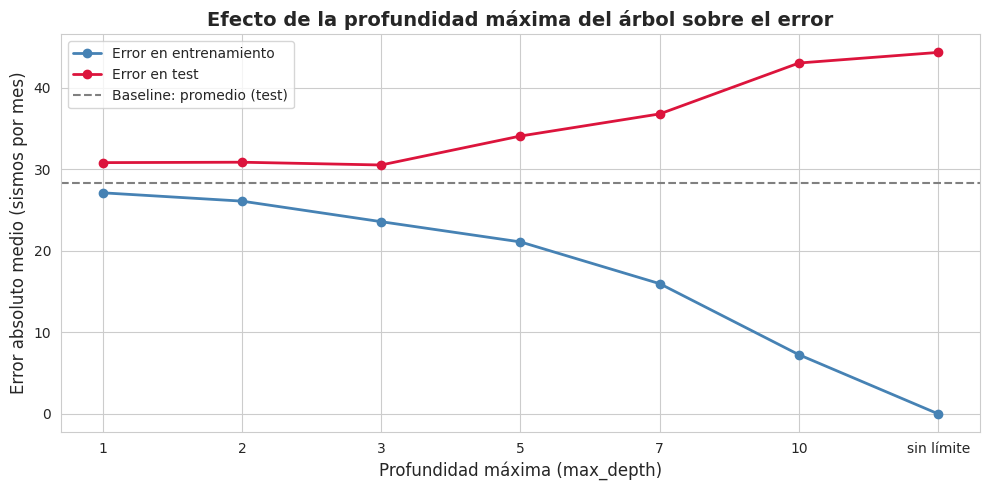

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

etiquetas = tabla_exp["max_depth"].astype(str)
ax.plot(etiquetas, tabla_exp["MAE train"], marker="o", linewidth=2, color="steelblue", label="Error en entrenamiento")
ax.plot(etiquetas, tabla_exp["MAE test"], marker="o", linewidth=2, color="crimson", label="Error en test")
ax.axhline(mean_absolute_error(y_test, pred_promedio), color="gray", linestyle="--",
           label="Baseline: promedio (test)")

ax.set_title("Efecto de la profundidad máxima del árbol sobre el error")
ax.set_xlabel("Profundidad máxima (max_depth)")
ax.set_ylabel("Error absoluto medio (sismos por mes)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.3 Interpretación
**¿Se cumplió la predicción?** Sí, en gran parte.
- El error de entrenamiento baja de forma constante al aumentar la profundidad (de ~27 a 0 sismos por mes). Con `max_depth` sin límite
  el árbol tiene casi una hoja por mes (478 hojas para 489 meses): memoriza el entrenamiento.
- El error de test sube al mismo tiempo: de ~31 con profundidad 3 a ~44 sin límite, y el R² llega a valores muy negativos (≈ -1).
  La distancia entre ambas curvas crece: es el **sobreajuste** clásico.
- Para profundidades 1, 2 y 3 el error en test es casi igual (~31): el modelo es simple y se parece al promedio, como esperábamos.
- Lo que no habíamos anticipado es que **ninguna profundidad supera al baseline del promedio** (MAE ≈ 28.3) en test. Incluso el árbol
  más simple queda un poco peor.

**¿Qué concluimos sobre el modelo?**
1. Más complejidad no ayuda: la señal que el árbol puede aprender de los 3 meses anteriores es muy débil y
   lo único que gana con más profundidad es memorizar ruido.
2. El problema no se arregla con un modelo más complejo. El límite parece estar en la información disponible (los datos), no en el algoritmo.

## 5. Auditoría del modelo

Para la auditoría volvemos al **modelo inicial** (`max_depth = 3`).

### 5.1 ¿Qué tan bien generaliza el modelo?

In [ ]:
print(resultados.loc[["Árbol (train)", "Árbol (test)"]])
print()
print("Correlación entre un mes y el mes anterior:")
print("  Entrenamiento:", round(y_train.corr(X_train["n_mes_1"]), 2))
print("  Test:         ", round(y_test.corr(X_test["n_mes_1"]), 2))

                 MAE   RMSE    R2
Árbol (train)  23.56  32.94  0.49
Árbol (test)   30.51  47.43 -0.03

Correlación entre un mes y el mes anterior:
  Entrenamiento: 0.35
  Test:          0.2


- El rendimiento empeora al pasar de entrenamiento a test: el MAE sube de ~24 a ~31 y el R² cae de ≈ 0.49 a ≈ 0.
  Esa diferencia indica sobreajuste: el árbol aprendió patrones del periodo 1973-2013 (por ejemplo, el
  efecto de unos pocos meses gigantes como marzo de 2011) que no se repiten en 2014-2025.
- Al mismo tiempo, el modelo en test no mejora al promedio. Esto no es solo sobreajuste: también muestra que
  las features tienen poca información sobre el futuro. Con `max_depth = 1` (el modelo más simple) tampoco
  se obtiene una mejora, así que tampoco es un problema de subajuste.
- Un dato importante: la correlación entre un mes y el anterior (calculada en la celda de arriba) es más baja en test que en
  entrenamiento. Es decir, la relación que el árbol aprendió era más débil y menos estable en los años recientes.

### 5.2 ¿Dónde falla el modelo?
Buscamos los meses del test con **mayor error** y miramos qué ocurrió en esos meses: cuál fue el terremoto más
grande y dónde.

In [ ]:
# Terremoto más grande de cada mes (magnitud y lugar)
idx_mayor = sismos5.groupby("mes")["mag"].idxmax()
mayor_sismo = sismos5.loc[idx_mayor, ["mes", "mag", "place"]].set_index("mes")
mayor_sismo.columns = ["mag_max_mes", "lugar_mayor_sismo"]

# Tabla de errores del test
errores = pd.DataFrame({
    "real": y_test,
    "prediccion": pred_test.round(0),
    "sismos_mes_anterior": X_test["n_mes_1"],
})
errores["error_abs"] = (errores["real"] - errores["prediccion"]).abs()
errores = errores.join(mayor_sismo)

# Los 8 mayores errores
errores.sort_values("error_abs", ascending=False).head(8)

,real,prediccion,sismos_mes_anterior,error_abs,mag_max_mes,lugar_mayor_sismo
2025-07-01,413,144.0,118.0,269.0,8.8,"2025 Kamchatka Peninsula, Russia Earthquake"
2021-03-01,364,172.0,274.0,192.0,8.1,"2021 Kermadec Islands, New Zealand Earthquake"
2021-08-01,335,143.0,149.0,192.0,8.1,2021 South Sandwich Islands Earthquake
2023-12-01,279,144.0,141.0,135.0,7.6,"19 km E of Gamut, Philippines"
2021-02-01,274,143.0,149.0,131.0,7.7,southeast of the Loyalty Islands
2014-04-01,245,143.0,161.0,102.0,8.2,"93 km NW of Iquique, Chile"
2016-12-01,245,143.0,172.0,102.0,7.9,"140 km E of Kokopo, Papua New Guinea"
2015-09-01,211,127.0,117.0,84.0,8.3,"48 km W of Illapel, Chile"


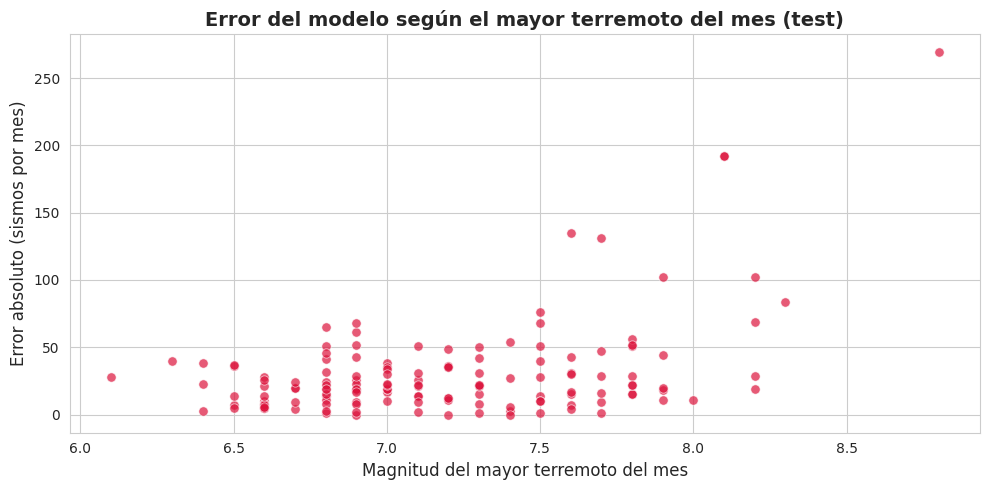

Meses con un terremoto M ≥ 7.5: 45 -> error medio = 49.7 sismos
Resto de los meses:            99 -> error medio = 21.7 sismos


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(data=errores, x="mag_max_mes", y="error_abs", color="crimson", s=45, alpha=0.7, ax=ax)

ax.set_title("Error del modelo según el mayor terremoto del mes (test)")
ax.set_xlabel("Magnitud del mayor terremoto del mes")
ax.set_ylabel("Error absoluto (sismos por mes)")
plt.tight_layout()
plt.show()

# Comparamos el error en meses con un terremoto muy grande vs. el resto
grandes = errores[errores["mag_max_mes"] >= 7.5]
resto = errores[errores["mag_max_mes"] < 7.5]
print(f"Meses con un terremoto M ≥ 7.5: {len(grandes)} -> error medio = {grandes['error_abs'].mean():.1f} sismos")
print(f"Resto de los meses:            {len(resto)} -> error medio = {resto['error_abs'].mean():.1f} sismos")

**Patrón observado**
- Los 8 mayores errores ocurren todos en meses con un terremoto muy grande (magnitud entre 7.6 y 8.8): por ejemplo
  julio de 2025 (Kamchatka, M 8.8), marzo de 2021 (Kermadec, M 8.1) o agosto de 2021 (Islas Sandwich del Sur, M 8.1).
  Estos terremotos generan cientos de réplicas de magnitud ≥ 5 en pocas semanas.
- En esos meses el modelo subestima mucho, porque no puede saber que va a ocurrir un terremoto grande: el sismo principal
  no se anuncia en los 3 meses anteriores.
- El error medio es más del doble en los meses con un sismo M ≥ 7.5 (≈ 50 sismos) que en el resto (≈ 22 sismos).
- En otras palabras, el modelo funciona mejor para meses "tranquilos" y falla justo en los meses que más nos   importarían (los excepcionales).

### 5.3 ¿Qué aprendimos que no era evidente con una única métrica global?
- El R² por sí solo podría llevarnos a pensar que "el modelo es malo en general". Pero el análisis de errores
  muestra algo más preciso: en la mayoría de los meses el error es moderado, y los errores enormes se concentran en
  muy pocos meses (los de terremotos gigantes).
- El MAE parecía aceptable (~31 sismos por mes, con un promedio de ~138). Pero al compararlo con el baseline del promedio, vimos que no aportaba nada: sin la comparación, habríamos creído que el modelo funcionaba.
- El experimento mostró que el error de entrenamiento (bajando hasta 0) es engañoso: un modelo que
  "se equivoca 0" en entrenamiento puede ser el peor en test.

### 5.4 ¿Cómo mejoraríamos el modelo?
Nuestra propuesta es separar la actividad "normal" de las réplicas. Los errores más grandes vienen de las
secuencias de réplicas de unos pocos terremotos gigantes, que dominan el conteo mensual. Podríamos:
1. **Eliminar las réplicas** del catálogo (técnica llamada *declustering*) y predecir solo el número de sismos
   "independientes" por mes, que debería ser mucho más estable y fácil de modelar.
2. Alternativamente, **cambiar el problema**: en lugar de predecir un número exacto, clasificar los meses entre
   "actividad normal" y "actividad excepcional", que es lo que realmente interesa en la práctica.

Justificación: los resultados muestran que (i) un modelo más complejo no ayuda (experimento) y (ii) los fallos se
concentran en meses con réplicas masivas (análisis de errores). Por lo tanto, la mejora debe venir de **cambiar la forma
de plantear el problema o los datos**, y no del algoritmo.

*(No implementamos esta mejora, tal como indica el enunciado.)*

## 6. Conclusiones

¿Qué tan confiable es nuestro modelo? Poco confiable para predecir cuántos terremotos habrá el próximo mes.
En test no mejora al baseline más simple (predecir el promedio histórico): su error es de ~31 sismos por mes, frente a ~28 del promedio,
y su R² es ≈ 0 (no explica más variación que el promedio).

Fortaleza: el planteamiento es metodológicamente cuidadoso. Usamos una separación cronológica, solo variables del
pasado, un catálogo homogéneo (magnitud ≥ 5.0 desde 1973) y baselines de comparación. Gracias a eso,
el resultado negativo es creíble y no un artefacto de errores metodológicos. Además, el árbol es fácil de interpretar
y el experimento mostró claramente el sobreajuste.

Limitación importante: los 3 meses anteriores contienen muy poca información sobre el mes siguiente. El conteo mensual
está dominado por réplicas de unos pocos terremotos gigantes que no se pueden anticipar, y el modelo falla justamente en esos
meses excepcionales.

Implicancia: una buena métrica no implica un modelo útil, y una mala métrica también es información.
Aquí el modelo nos enseña algo sobre los datos: los terremotos son, a escala mensual, muy difíciles de predecir
con solo el historial reciente. Este resultado también conecta con la Tarea 1: la serie mensual de sismos M ≥ 5 no muestra
una tendencia clara, así que no hay evidencia en estos datos de que "esté temblando más" una vez que corregimos el
problema de detección.

---

### Uso de herramientas de inteligencia artificial
Utilizamos una herramienta de IA como apoyo para estructurar el notebook (actualización y gráficos).